# Características de las retinografías locales

## Pregunta

¿Qué diferencias de brillo, color, fondo, nitidez y encuadre aparecen por fuente, etiqueta y partición, y cuáles se observan al comparar originales con sus derivados verificados?

| Hallazgo en el notebook de Andrés | Decisión | Comprobación |
| --- | --- | --- |
| RGB medio y relleno cambian según etiqueta Moondream | Empezar con promedios de toda la imagen y esquinas, y añadir medidas de región visible | Cajas por clase, auditoría de rangos y tablas por split |
| Hay duplicados exactos y probables | Comparar Moondream original, reconstruido y elegible | Manifiesto o reconstrucción, cruce por ruta y conteos |
| La cabeza ganadora usa tres clases y τ=0,95 | Exigir predicciones verificadas para asociaciones con errores | Cobertura de ruta y huellas del archivo, checkpoint, split y elegibilidad |

Referencias locales [Método](resultados_y_datos/caracteristicas_retinografias/METODO.md), [Informe](resultados_y_datos/caracteristicas_retinografias/INFORME.md) y [Notebook de Andrés](../Andres_Arbelaez/Comprobacion_mejor_modelo.ipynb).

**Ejecución registrada.** Piloto con 27 archivos recalculados y ejecución completa con 54. Se analizaron los 8.242 registros históricos y 2.096 pares verificados. Debajo se guardan las salidas de la ejecución completa.

## Configuración

Ejecuta desde la raíz del repositorio o desde `Fabian/`. El modo predeterminado es piloto. Define `FABIAN_MODO=completo` antes de iniciar Jupyter para usar todos los datos elegibles. Puedes cambiar `FABIAN_REPO`, `FABIAN_SALIDA`, `FABIAN_SPLITS_ANDRES` y `FABIAN_CHECKPOINT_ANDRES`. `FABIAN_SHA256_ANDRES` admite una huella obtenida de la fuente del checkpoint. Las salidas de piloto y completo tienen carpetas propias en el directorio local de Fabián. Este bloque registra las versiones y crea esas carpetas.

In [1]:
%matplotlib inline
import ast
import hashlib
import json
import os
import platform
import random
import re
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image
from sklearn.model_selection import train_test_split

ROOT = Path(os.environ.get("FABIAN_REPO", Path.cwd())).resolve()
if ROOT.name == "Fabian":
    ROOT = ROOT.parent
assert (ROOT / "Andres_Arbelaez/Comprobacion_mejor_modelo.ipynb").is_file(), "Configura FABIAN_REPO con la raíz"
HIST = ROOT / "Fabian/resultados_y_datos/caracteristicas_retinografias"
SCRIPTS = ROOT / "Fabian/codigos_y_scripts"
OUTPUT = Path(os.environ.get("FABIAN_SALIDA", Path(os.environ.get("LOCALAPPDATA", Path.home() / ".cache")) / "glaucoma-fabian"))
PILOT = os.environ.get("FABIAN_MODO", "piloto") != "completo"
SEED = 42
RUN = OUTPUT / ("piloto" if PILOT else "completo")
AUDIT = OUTPUT / "auditoria"
AUDIT.mkdir(parents=True, exist_ok=True)
RUN.mkdir(parents=True, exist_ok=True)
MANIFEST = Path(os.environ.get("FABIAN_SPLITS_ANDRES", ROOT / "Andres_Arbelaez/resultados_y_datos/splits_moondream.csv"))
CHECKPOINT = Path(os.environ.get("FABIAN_CHECKPOINT_ANDRES", ROOT / "modelos/convnext_tiny_final.pth"))
CHECKPOINT_SHA = os.environ.get("FABIAN_SHA256_ANDRES", "").lower().strip()
MOON = "Moondream Staged"
CLASSES = ["Sano", "Etapa inicial", "Avanzado"]
BINARY = ["Sano", "Positivo"]
ENC = {"normal": 0, "early": 1, "advanced": 2}
COLORS = ["#137b80", "#c28616", "#8c3265"]
SOURCE_COLORS = ["#4069a0", "#bd7144", "#498574", "#89659a", "#9b842b"]
print(f"Modo {'piloto' if PILOT else 'completo'} · semilla {SEED} · salidas {RUN}")
print("Python", platform.python_version(), "|", {p: version(p) for p in ("numpy", "pandas", "Pillow", "scikit-learn", "matplotlib")})

def image_rgb(path):
    with Image.open(ROOT / path) as image:
        return image.convert("RGB")

def digest(path, algorithm="sha256"):
    with (ROOT / path).open("rb") as stream:
        return hashlib.file_digest(stream, algorithm).hexdigest()

def read_history(name):
    path = HIST / f"{name}.csv"
    return pd.read_csv(path, low_memory=False) if path.is_file() else pd.DataFrame()

def percentile_table(data, group, metrics):
    out = data.melt(id_vars=group, value_vars=list(metrics), var_name="medida", value_name="valor")
    out = out.groupby(group + ["medida"], dropna=False, sort=False)["valor"].agg(
        n="size", válidos="count", p25=lambda s: s.quantile(.25), mediana="median",
        p75=lambda s: s.quantile(.75)).reset_index()
    out["faltantes"] = out.n - out.válidos
    out["RIC"] = out.p75 - out.p25
    return out

def stratified_sample(data, keys, limit):
    if data.empty:
        return data.copy()
    groups = data.groupby(keys, dropna=False, sort=False)
    return pd.concat([g.sample(n=min(limit, len(g)), random_state=SEED) for _, g in groups]).sort_index()

Modo completo · semilla 42 · salidas C:\Users\fabi2\AppData\Local\glaucoma-fabian\completo
Python 3.14.2 | {'numpy': '2.4.0', 'pandas': '2.3.3', 'Pillow': '12.0.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.10.8'}


## Datos y auditoría

### Reconstrucción de la partición de Andrés

Se indexan `train`, luego `test`, en el orden `normal`, `early`, `advanced`, con rutas ordenadas en cada clase. ResNet-18 con pesos ImageNet de torchvision y sin cabeza produce vectores normalizados L2. Su entrada es RGB, redimensionada a 224 × 224 con interpolación bilineal y normalizada con media y DE de ImageNet. Se ensayan cosenos 0,99/0,98/0,97/0,96 y se aplican **0,96 y MD5 idéntico** en un cierre transitivo. Se elimina por completo cada grupo con etiquetas contradictorias. En los demás se conserva el primer archivo en el orden de entrada. La división estratificada reserva 15 % para test y 17,65 % del resto para validación. Ambas llamadas usan semilla 42. El manifiesto publicado, cuando está disponible, se compara por ruta relativa, etiqueta, partición y orden. Hasta entonces, el resultado de este bloque se denomina **reconstrucción sin confirmar**.

In [2]:
import torch
import torchvision
from torchvision import transforms as T
from torchvision.models import ConvNeXt_Tiny_Weights, ResNet18_Weights, convnext_tiny, resnet18

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(min(6, os.cpu_count() or 1))
MEAN, STD = [.485, .456, .406], [.229, .224, .225]
EVAL_PIL = T.Resize((224, 224))
TO_MODEL = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
TF_EVAL = T.Compose([EVAL_PIL, TO_MODEL])
MOON_DIR = ROOT / "data/MOONDREAM_STAGED"
EXPECTED = pd.DataFrame([[274, 127, 131], [59, 27, 29], [59, 27, 29]],
                        index=["train", "val", "test"], columns=list(ENC))
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| dispositivo", DEVICE)

class Components:
    def __init__(self, keys):
        self.parent = {key: key for key in keys}

    def find(self, key):
        while self.parent[key] != key:
            self.parent[key] = self.parent[self.parent[key]]
            key = self.parent[key]
        return key

    def link(self, a, b):
        self.parent[self.find(a)] = self.find(b)

def moon_pool():
    rows = []
    for split in ("train", "test"):
        for label in ENC:
            for path in sorted((MOON_DIR / split / label).rglob("*")):
                if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                    relative = path.relative_to(ROOT).as_posix()
                    rows.append({"id": relative, "original": split, "clase": label, "md5": digest(relative, "md5")})
    return pd.DataFrame(rows, columns=["id", "original", "clase", "md5"])

def scenario_signature(rows):
    return hashlib.sha256(rows.to_csv(index=False).encode("utf-8")).hexdigest()

def reconstruct(pool):
    weights = ResNet18_Weights.DEFAULT
    signature = scenario_signature(pool)
    cache = AUDIT / f"resnet18_{signature[:16]}_{DEVICE}_{torch.__version__.split('+')[0]}_{torchvision.__version__.split('+')[0]}.npz"
    if cache.is_file():
        embeddings = np.load(cache)["embeddings"]
    else:
        model = resnet18(weights=weights)
        model.fc = torch.nn.Identity()
        model = model.eval().to(DEVICE)
        blocks = []
        with torch.inference_mode():
            for start in range(0, len(pool), 64):
                batch = torch.stack([TF_EVAL(image_rgb(p)) for p in pool.id.iloc[start:start + 64]])
                blocks.append(torch.nn.functional.normalize(model(batch.to(DEVICE)), dim=1).cpu())
        embeddings = torch.cat(blocks).numpy()
        with cache.with_suffix(".tmp").open("wb") as stream:
            np.savez_compressed(stream, embeddings=embeddings)
        cache.with_suffix(".tmp").replace(cache)
        del model
    vectors = torch.from_numpy(embeddings)
    similarity = (vectors @ vectors.T).numpy()
    component = Components(pool.id)
    sensitivity = []
    original = pool.original.to_numpy()
    ids = pool.id.to_numpy()
    for threshold in (.99, .98, .97, .96):
        a, b = np.where(np.triu(similarity >= threshold, 1))
        sensitivity.append([threshold, len(a), int((original[a] != original[b]).sum())])
        if threshold == .96:
            for left, right in zip(ids[a], ids[b]):
                component.link(left, right)
            cosine_pairs = pd.DataFrame({"a": ids[a], "b": ids[b], "coseno": similarity[a, b]})
    for _, group in pool.groupby("md5"):
        for key in group.id.iloc[1:]:
            component.link(group.id.iloc[0], key)
    grouped = pool.assign(grupo=pool.id.map(component.find))
    conflicts = grouped.groupby("grupo").clase.nunique().loc[lambda s: s > 1].index
    valid = grouped.loc[~grouped.grupo.isin(conflicts)]
    clean = valid.drop_duplicates("grupo")
    trainval, test = train_test_split(clean, test_size=.15, stratify=clean.clase, random_state=42)
    train, val = train_test_split(trainval, test_size=.1765, stratify=trainval.clase, random_state=42)
    new = pd.concat([g[["id", "clase"]].assign(split=label)
                     for g, label in ((train, "train"), (val, "val"), (test, "test"))], ignore_index=True)
    info = pd.DataFrame(sensitivity, columns=["umbral", "pares", "cruces train/test originales"])
    print(f"Grupos MD5 que cruzan el split original: {pool.groupby('md5').original.nunique().gt(1).sum()}")
    print(f"Archivos originales: {len(pool)} · sin conflicto: {len(valid)} · representantes: {len(clean)} · grupos con conflicto: {len(conflicts)}")
    display(info)
    grouped.to_csv(AUDIT / "grupos_andres_reconstruidos.csv", index=False)
    return new, cosine_pairs

def normalize_moon_path(value):
    normalized = str(value).replace(chr(92), "/")
    marker = "MOONDREAM_STAGED/"
    assert marker in normalized, f"Ruta ajena a Moondream: {normalized}"
    return "data/" + normalized[normalized.index(marker):]

def counts(table):
    return pd.crosstab(table.split, table.clase).reindex(index=EXPECTED.index, columns=EXPECTED.columns, fill_value=0)

POOL = moon_pool()
REF = pd.DataFrame(columns=["id", "clase", "split"])
COSINE = pd.DataFrame(columns=["a", "b", "coseno"])
REF_STATUS = "Sin datos locales suficientes"
REF_CONFIRMED = False
if not POOL.empty and POOL.groupby("clase").size().min() >= 12 and POOL.clase.nunique() == 3:
    REBUILT, COSINE = reconstruct(POOL)
    REBUILT.to_csv(AUDIT / "splits_moondream_reconstruido.csv", index=False)
    REF, REF_STATUS = REBUILT, "Reconstrucción sin confirmar"
    if MANIFEST.is_file():
        published = pd.read_csv(MANIFEST, encoding="utf-8-sig")
        published = published.assign(id=published.ruta.map(normalize_moon_path))[["id", "clase", "split"]]
        assert published.id.is_unique, "Rutas repetidas en el manifiesto de Andrés"
        assert published.clase.eq(published.id.map(POOL.set_index("id").clase)).all(), "Rutas o etiquetas del manifiesto inválidas"
        assert counts(published).equals(EXPECTED) and len(published) == 762, "Conteos del manifiesto distintos de la bitácora"
        diff = published.merge(REBUILT, on=["id", "clase", "split"], how="outer", indicator=True)
        display(diff["_merge"].value_counts().rename("rutas y etiquetas por split"))
        print("Mismo orden de filas:", published.reset_index(drop=True).equals(REBUILT))
        REF, REF_STATUS, REF_CONFIRMED = published, "Manifiesto de Andrés aportado y comprobado contra los archivos locales", True
    else:
        print(f"Manifiesto publicado ausente: {MANIFEST}. Los conteos carecen de evidencia de identidad por ruta.")
    display(pd.concat({"Disponible": counts(REF), "Publicado": EXPECTED}, axis=1))
print(REF_STATUS)
assert REF.empty or REF.id.is_unique

PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126 | dispositivo cuda


Grupos MD5 que cruzan el split original: 12
Archivos originales: 800 · sin conflicto: 800 · representantes: 762 · grupos con conflicto: 0


,umbral,pares,cruces train/test originales
0,0.99,34,12
1,0.98,34,12
2,0.97,35,12
3,0.96,38,13


Manifiesto publicado ausente: C:\Users\fabi2\OneDrive\Escritorio\ProyectoDL-Grupo2-Glaucoma\Andres_Arbelaez\resultados_y_datos\splits_moondream.csv. Los conteos carecen de evidencia de identidad por ruta.


Disponible                Publicado               
          normal early advanced    normal early advanced
train        274   127      131       274   127      131
val           59    27       29        59    27       29
test          59    27       29        59    27       29

Reconstrucción sin confirmar


### Cruces en la referencia y entre fuentes

Se comprueba SHA-256 contra el inventario de las cinco fuentes originales y se enlazan coincidencias exactas de píxeles, pares SIFT/RANSAC, coseno del protocolo de Andrés y originales/derivados de procedencia verificada en la corrida histórica. Los códigos r3 de RIM con lateralidad se agrupan de forma conservadora cuando comparten el prefijo numérico. Moondream y las demás colecciones carecen de un identificador de paciente verificable en los insumos usados. Los grupos sirven para proteger la evaluación frente a variantes visuales y su interpretación queda a nivel de archivo. La búsqueda geométrica histórica puede omitir espejados o recortes severos.

Se conserva la partición de referencia y se crea una vista elegible separada. Ante un cruce se mantiene el representante compatible con la prioridad train → validación → test. Así se protege el test frente a grupos vistos por un checkpoint que hubiese usado el train publicado. En una misma partición se conserva una ruta estable por grupo. Se excluyen los grupos con conflicto dentro de un esquema y las imágenes externas vinculadas con cualquier archivo del pool Moondream. Los derivados enlazan sus fuentes y quedan fuera del denominador externo. Se registran las exclusiones por ruta, incluidos los motivos, y se tabulan cohortes con sus denominadores.

En Moondream, «Glaucoma» en la cabeza de Andrés significa **Avanzado**. En ACRIMA y RIM-ONE DL significa **positivo binario** según su fuente. En EyePACS REAL se usan las clases de cribado locales RG/NRG. Se optó por mantener incluso los sanos de referencia binaria fuera de la fila Sano trinaria. Su aporte queda registrado en la fila Sano de cada evaluación binaria externa.

In [3]:
from collections import defaultdict

HROWS = read_history("por_imagen")
GEOMETRY = read_history("coincidencias_geometricas")
EXACT = read_history("duplicados")
COHORTS = ["ACRIMA", "RIM-ONE DL", "EyePACS REAL"]
INTERNAL = "Moondream · test"

def control_eligibility():
    if any(table.empty for table in (HROWS, GEOMETRY, EXACT)):
        print("Auditoría de cruces pendiente: faltan por_imagen.csv o las tablas históricas de coincidencias.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
    assert HROWS.id_imagen.is_unique
    primary = HROWS.loc[HROWS.coleccion.isin([MOON, *COHORTS, "EyePACS TRAIN"])].copy()
    primary["verificado"] = [
        (ROOT / p).is_file() and digest(p) == sha
        for p, sha in primary[["id_imagen", "sha256_archivo"]].itertuples(index=False, name=None)
    ]
    print(f"Rutas SHA-256 vigentes: {primary.verificado.sum()}/{len(primary)} en las cinco cohortes originales.")
    moon_valid = set(primary.loc[primary.coleccion.eq(MOON) & primary.verificado, "id_imagen"])
    if not set(REF.id).issubset(moon_valid):
        print("Cobertura incompleta en la auditoría de Moondream. Se suspende la evaluación hasta actualizar el inventario.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    graph = Components(HROWS.id_imagen)
    edges = []

    def link(a, b, evidence):
        if a != b and a in graph.parent and b in graph.parent:
            graph.link(a, b)
            edges.append((a, b, evidence))

    for _, rows in EXACT.groupby("sha256_pixeles"):
        for path in rows.id_imagen.iloc[1:]:
            link(rows.id_imagen.iloc[0], path, "píxeles idénticos")
    for a, b in GEOMETRY[["id_a", "id_b"]].itertuples(index=False, name=None):
        link(a, b, "SIFT/RANSAC histórico")
    for a, b in HROWS.loc[HROWS.estado_par.isin(["verificado_bytes", "verificado_pixeles_aproximados"]),
                          ["id_imagen", "id_original"]].itertuples(index=False, name=None):
        link(a, b, "derivado de origen verificado en la corrida histórica")
    for a, b, cosine in COSINE.itertuples(index=False, name=None):
        link(a, b, f"coseno ResNet-18 {cosine:.3f}")
    for _, rows in POOL.groupby("md5"):
        for key in rows.id.iloc[1:]:
            link(rows.id.iloc[0], key, "MD5 idéntico")
    rim = primary.loc[primary.coleccion.eq("RIM-ONE DL")].copy()
    rim["identificador_candidato"] = rim.archivo.str.extract(r"^(r3_[A-Z]-\d+)-[LR]_")[0]
    for _, rows in rim.dropna(subset=["identificador_candidato"]).groupby("identificador_candidato"):
        for path in rows.id_imagen.iloc[1:]:
            link(rows.id_imagen.iloc[0], path, "código r3 compartido (agrupación conservadora)")

    reference = REF.assign(coleccion=MOON, grupo=REF.id.map(graph.find), verificado=True)
    external = primary.loc[primary.coleccion.isin(COHORTS), ["id_imagen", "coleccion", "etiqueta", "verificado"]]
    external = external.rename(columns={"id_imagen": "id", "etiqueta": "clase"}).assign(split="externo")
    external["grupo"] = external.id.map(graph.find)
    work = pd.concat([reference, external], ignore_index=True)
    original_labels = POOL.assign(grupo=POOL.id.map(graph.find))
    moon_groups = set(original_labels.grupo)
    conflict_moon = set(original_labels.groupby("grupo").clase.nunique().loc[lambda s: s > 1].index)
    bad_external = external.groupby(["grupo", "coleccion"]).clase.nunique().loc[lambda s: s > 1].index
    work["estado"] = "elegible"
    work.loc[~work.verificado, "estado"] = "archivo ausente o SHA-256 distinto"
    work.loc[work.coleccion.eq(MOON) & work.grupo.isin(conflict_moon), "estado"] = "grupo Moondream con etiquetas contradictorias"
    work.loc[work.split.eq("externo") & ~work.clase.isin(["normal", "glaucoma"]), "estado"] = "referencia binaria ausente"
    work.loc[work.split.eq("externo") & work.grupo.isin(moon_groups), "estado"] = "vínculo con el pool original Moondream"
    for group, source in bad_external:
        work.loc[work.grupo.eq(group) & work.coleccion.eq(source), "estado"] = "conflicto binario dentro de la fuente"
    grouped = work.loc[work.estado.eq("elegible")].groupby("grupo", sort=False)
    priority = {"train": 0, "val": 1, "test": 2, "externo": 3}
    source_order = {source: index for index, source in enumerate([MOON, *COHORTS])}
    for _, rows in grouped:
        ordered = rows.assign(prioridad=rows.split.map(priority), fuente=rows.coleccion.map(source_order))
        ordered = ordered.sort_values(["prioridad", "fuente", "id"])
        first = ordered.iloc[0]
        for item in ordered.iloc[1:].itertuples():
            work.loc[item.Index, "estado"] = (
                f"grupo compartido con {first.split}" if first.split != item.split else "otro representante del grupo"
            )
    pairs = pd.DataFrame(edges, columns=["a", "b", "evidencia"])
    reference_role = reference.set_index("id").split
    roles = work.set_index("id").split
    sources = HROWS.set_index("id_imagen").coleccion
    pairs["split_a"], pairs["split_b"] = pairs.a.map(roles), pairs.b.map(roles)
    pairs["fuente_a"], pairs["fuente_b"] = pairs.a.map(sources), pairs.b.map(sources)
    direct = pairs.loc[(pairs.split_a.notna() & pairs.split_b.notna() & pairs.split_a.ne(pairs.split_b))
                       | pairs.fuente_a.ne(pairs.fuente_b)]
    detail = work.groupby(["coleccion", "split", "estado"], sort=False).size().rename("n").reset_index()
    reference_links = reference.groupby("grupo").split.nunique().gt(1)
    print(f"Componentes de la referencia con cruce train/val/test: {reference_links.sum()}.")
    print(f"Enlaces directos interpartición/interfuente: {len(direct)} (incluyen derivados).")
    display(detail)
    work.to_csv(AUDIT / "elegibilidad_por_imagen.csv", index=False)
    direct.to_csv(AUDIT / "enlaces_interparticion_o_fuente.csv", index=False)
    keep = work.loc[work.estado.eq("elegible")].copy()
    assert keep.grupo.is_unique
    keep["y3"] = keep.clase.map(ENC).where(keep.coleccion.eq(MOON))
    keep["y2"] = keep.clase.ne("normal").astype(int)
    return keep, direct, work

ELIGIBLE, LINKS, DECISIONS = control_eligibility()
catalog = [
    [MOON, "MOONDREAM_STAGED · copia local", "Carpetas + split de Andrés/reconstrucción", "70/15/15 de referencia", "Trinaria local", "normal / early / advanced", "Entrenamiento, validación, detección y estadio interno"],
    ["ACRIMA", "Database/Images · recortes", "Database/Readme.txt + nombres", "Externa, sin split oficial local", "Binaria anotada", "normal / glaucoma", "Detección externa"],
    ["RIM-ONE DL", "RIM_ONE_DL · recortes", "metadata.csv · etiqueta por ruta", "Externa, sin split oficial local", "Binaria del manifiesto", "normal / glaucoma", "Detección externa; incluye la clasificación local de serie S"],
    ["EyePACS REAL", "EYEPACS_REAL · muestras RG/NRG", "Carpetas + nombres RG/NRG", "Prueba externa del proyecto", "Binaria local de cribado", "normal / glaucoma", "Detección exploratoria según referencia RG/NRG"],
    ["EyePACS TRAIN", "EYEPACS_TRAIN · serie BEH", "Carpetas", "Entrenamiento del proyecto", "Binaria de carpeta", "normal / glaucoma", "Descripción y auditoría; fuera del entrenamiento de este estudio"],
    ["Megacohorte", "HARMONIZED_MEGA_COHORT · derivados", "results/harmonized_mega_cohort_index.csv", "train/test históricos", "Binaria recodificada", "normal / glaucoma", "Auditoría de procedencia y análisis de transformaciones"],
    ["THIRD_DATASET", "THIRD_DATASET · mapas RGBA", "Carpetas", "Sin partición verificable", "Binaria de carpeta; origen incierto", "non_glaucoma / glaucoma", "Descripción del archivo"],
    ["Web emulada", "WEB_IN_THE_WILD · derivados y distractores", "Pares comprobados con ACRIMA", "raw/filtered/rejected", "Origen binario parcial; derivados", "normal en pares de ACRIMA", "Descripción y comparación de procesamiento"],
    ["Google de Andrés", "Drive privado · lote de 588 reportado", "manifiesto.csv de limpieza, ausente", "Colección exploratoria", "Sin referencia verificada", "Sin etiquetas supervisadas", "Exploración sin métricas de clasificación"],
]
TABLE = pd.DataFrame(catalog, columns=["Fuente", "Versión local", "Manifiesto", "Partición", "Nivel", "Clases", "Uso"])
if not HROWS.empty:
    TABLE["n inventario histórico"] = TABLE.Fuente.map(HROWS.coleccion.value_counts()).fillna(0).astype(int)
if not ELIGIBLE.empty:
    TABLE["n elegible (todos los splits)"] = TABLE.Fuente.map(ELIGIBLE.coleccion.value_counts()).fillna(0).astype(int)
display(TABLE)

Rutas SHA-256 vigentes: 2352/2352 en las cinco cohortes originales.


Componentes de la referencia con cruce train/val/test: 25.
Enlaces directos interpartición/interfuente: 3044 (incluyen derivados).


,coleccion,split,estado,n
0,Moondream Staged,train,elegible,504
1,Moondream Staged,train,otro representante del grupo,28
2,Moondream Staged,val,elegible,107
3,Moondream Staged,val,grupo compartido con train,8
4,Moondream Staged,test,elegible,95
5,Moondream Staged,test,grupo compartido con train,10
6,Moondream Staged,test,otro representante del grupo,2
7,Moondream Staged,test,grupo compartido con val,8
8,ACRIMA,externo,elegible,703
9,ACRIMA,externo,otro representante del grupo,2


,Fuente,Versión local,Manifiesto,Partición,Nivel,Clases,Uso,n inventario histórico,n elegible (todos los splits)
0,Moondream Staged,MOONDREAM_STAGED · copia local,Carpetas + split de Andrés/reconstrucción,70/15/15 de referencia,Trinaria local,normal / early / advanced,"Entrenamiento, validación, detección y estadio...",800,706
1,ACRIMA,Database/Images · recortes,Database/Readme.txt + nombres,"Externa, sin split oficial local",Binaria anotada,normal / glaucoma,Detección externa,705,703
2,RIM-ONE DL,RIM_ONE_DL · recortes,metadata.csv · etiqueta por ruta,"Externa, sin split oficial local",Binaria del manifiesto,normal / glaucoma,Detección externa; incluye la clasificación lo...,447,447
3,EyePACS REAL,EYEPACS_REAL · muestras RG/NRG,Carpetas + nombres RG/NRG,Prueba externa del proyecto,Binaria local de cribado,normal / glaucoma,Detección exploratoria según referencia RG/NRG,200,200
4,EyePACS TRAIN,EYEPACS_TRAIN · serie BEH,Carpetas,Entrenamiento del proyecto,Binaria de carpeta,normal / glaucoma,Descripción y auditoría; fuera del entrenamien...,200,0
5,Megacohorte,HARMONIZED_MEGA_COHORT · derivados,results/harmonized_mega_cohort_index.csv,train/test históricos,Binaria recodificada,normal / glaucoma,Auditoría de procedencia y análisis de transfo...,2937,0
6,THIRD_DATASET,THIRD_DATASET · mapas RGBA,Carpetas,Sin partición verificable,Binaria de carpeta; origen incierto,non_glaucoma / glaucoma,Descripción del archivo,2805,0
7,Web emulada,WEB_IN_THE_WILD · derivados y distractores,Pares comprobados con ACRIMA,raw/filtered/rejected,Origen binario parcial; derivados,normal en pares de ACRIMA,Descripción y comparación de procesamiento,148,0
8,Google de Andrés,Drive privado · lote de 588 reportado,"manifiesto.csv de limpieza, ausente",Colección exploratoria,Sin referencia verificada,Sin etiquetas supervisadas,Exploración sin métricas de clasificación,0,0


### Auditoría de esta ejecución

Los conteos del protocolo de Andrés coincidieron con su bitácora a los cuatro umbrales. En la reconstrucción local hubo **27 enlaces directos SIFT/RANSAC** entre train, validación y test, y **cero enlaces directos por MD5, píxeles idénticos o coseno ≥0,96** entre esas particiones. La unión transitiva marcó 25 componentes entre particiones. Se apartaron 28 archivos de train, 8 de validación y 20 de test. La vista de análisis quedó en **504/107/95**. Los vínculos directos entre fuentes del inventario enlazaron originales y derivados históricos. Los dos archivos externos descartados eran representantes adicionales de grupos ACRIMA.

## Método

Se cargan `por_imagen.csv`, `pares.csv`, `resumen_pares.csv` y las tablas de coincidencias históricas. Se verifica que las rutas de las mediciones sean únicas y se controlan rangos en toda la tabla. Se recalculan métricas del extractor original y se verifican correspondencias con los scripts de Fabián en una muestra estratificada. El piloto recalcula hasta tres archivos por fuente y tipo y dos pares por fuente y transformación. La versión completa amplía a seis y cuatro, respectivamente. Las descripciones y tablas se calculan con todo el inventario histórico en ambos modos.

La luma es Y′ en niveles digitales de 8 bits. Contraste es su DE poblacional en la región estimada. Casi negro es máximo RGB ≤10. Saturación y área visible se expresan en porcentaje, ancho y alto en píxeles y centros/extensiones en fracciones del marco. La nitidez se mide con varianza del Laplaciano en resolución nativa y con lado largo de 512 px. El fondo de esquina evalúa otra señal, con la definición de Andrés. Se conservan los faltantes de distribuciones y pares.

In [4]:
sys.path.insert(0, str(SCRIPTS))
import cv2
from metricas_retinografias import measure
from procedencia_retinografias import pair_candidates, verify_pair

FEATURES = {
    "brillo_mediano_yn": "Brillo mediano (luma, 0–255)",
    "contraste_de_yn": "Contraste (DE de luma)",
    "r_media": "Rojo medio (0–255)",
    "g_media": "Verde medio (0–255)",
    "b_media": "Azul medio (0–255)",
    "saturacion_media_pct": "Saturación (%)",
    "ancho_px": "Ancho almacenado (px)",
    "alto_px": "Alto almacenado (px)",
    "laplaciano_nativo": "Varianza Laplaciano (nativa)",
    "laplaciano_lado512": "Varianza Laplaciano (lado largo 512 px)",
    "negro_pct": "Píxeles casi negros (%)",
    "negro_borde_pct": "Casi negro en borde (%)",
    "region_pct": "Área visible (%)",
    "centro_x": "Centro X (fracción del ancho)",
    "centro_y": "Centro Y (fracción del alto)",
    "extension_x": "Extensión horizontal (fracción)",
    "extension_y": "Extensión vertical (fracción)",
}
PAIR = read_history("pares")
PAIR_SUMMARY = read_history("resumen_pares")
print("OpenCV", cv2.__version__)
for name in ("METODO.md", "INFORME.md"):
    path = HIST / name
    if path.is_file():
        print(f"{name} · {path.read_text(encoding='utf-8').splitlines()[0]}")
if not HROWS.empty:
    assert HROWS.id_imagen.is_unique and HROWS.id_imagen.eq(HROWS.ruta_relativa).all()
    bounded = [k for k in FEATURES if k.endswith("_pct")]
    for column in bounded:
        assert HROWS[column].dropna().between(0, 100).all(), column
    for column in ("r_media", "g_media", "b_media", "brillo_mediano_yn", "contraste_de_yn"):
        assert HROWS[column].dropna().between(0, 255).all(), column
    for column in ("centro_x", "centro_y", "extension_x", "extension_y"):
        assert HROWS[column].dropna().between(0, 1).all(), column
    for column in ("ancho_px", "alto_px", "laplaciano_nativo", "laplaciano_lado512"):
        assert HROWS[column].dropna().ge(0).all(), column
    verification = HROWS.loc[HROWS.sha256_archivo.notna()]
    verification = stratified_sample(verification, ["coleccion", "tipo"], 3 if PILOT else 6)
    review = []
    for row in verification.itertuples():
        path = ROOT / row.id_imagen
        if not path.is_file():
            review.append({"fuente": row.coleccion, "ruta": row.id_imagen, "archivo coincide": False, "métricas cotejadas": 0})
            continue
        measured = measure(path, row.tipo)
        differences = [abs(float(getattr(row, k)) - measured[k]) for k in FEATURES
                       if measured.get(k) is not None and pd.notna(getattr(row, k))]
        missing_mismatch = sum(pd.isna(measured.get(k)) != pd.isna(getattr(row, k)) for k in FEATURES)
        review.append({"fuente": row.coleccion, "ruta": row.id_imagen,
                       "archivo coincide": measured["sha256_archivo"] == row.sha256_archivo,
                       "píxeles coinciden": measured["sha256_pixeles"] == row.sha256_pixeles,
                       "métricas cotejadas": len(differences), "faltantes discordantes": missing_mismatch,
                       "máxima diferencia": max(differences, default=np.nan)})
    verification_report = pd.DataFrame(review)
    if len(verification_report):
        display(verification_report.groupby("fuente").agg(
            n=("ruta", "size"), SHA256=("archivo coincide", "sum"),
            métricas=("métricas cotejadas", "sum"), discordancias=("faltantes discordantes", "sum"),
            diferencia_máxima=("máxima diferencia", "max")).round(6))
        assert verification_report["archivo coincide"].all() and verification_report["píxeles coinciden"].all()
        assert verification_report["faltantes discordantes"].eq(0).all()
        assert verification_report["máxima diferencia"].dropna().le(.001).all()
        verification_report.to_csv(RUN / "03_recalculo_verificacion.csv", index=False)
    if not PAIR.empty:
        assert PAIR.grupo_original.notna().all()
        assert not PAIR.duplicated(["grupo_original", "transformacion"]).any()
        assert set(PAIR.estado_par).issubset({"verificado_bytes", "verificado_pixeles_aproximados"})
        sources = HROWS.set_index("id_imagen")
        assert set(PAIR.id_original).union(PAIR.id_derivada).issubset(sources.index)
        assert PAIR.id_derivada.map(sources.id_original).eq(PAIR.id_original).all()
        sample_pairs = stratified_sample(PAIR, ["fuente", "transformacion"], 2 if PILOT else 4)
        source_config = json.loads((SCRIPTS / "fuentes_retinografias.json").read_text(encoding="utf-8-sig"))
        candidates = pair_candidates([dict(row, path=ROOT / row["id_imagen"]) for row in HROWS.to_dict("records")],
                                     source_config["fuentes"])
        local_pairs = []
        for row in sample_pairs.itertuples():
            observed = sources.loc[row.id_derivada].to_dict()
            observed.update(id_imagen=row.id_derivada, path=ROOT / row.id_derivada)
            assert digest(row.id_derivada) == observed["sha256_archivo"]
            assert digest(row.id_original) == sources.loc[row.id_original, "sha256_archivo"]
            result = verify_pair(observed, candidates.get(row.id_derivada))
            local_pairs.append({"fuente": row.fuente, "transformación": row.transformacion,
                                "coincide": result.get("id_original") == row.id_original})
        display(pd.DataFrame(local_pairs).groupby(["fuente", "transformación"]).coincide.agg(["size", "sum"]))
        assert all(result["coincide"] for result in local_pairs)

OpenCV 5.0.0
METODO.md · # Método de extracción y reproducción
INFORME.md · # Características visuales de las retinografías locales


,n,SHA256,métricas,discordancias,diferencia_máxima
fuente,,,,,
ACRIMA,6,6,102,0,0.000004
EyePACS REAL,6,6,102,0,0.000005
EyePACS TRAIN,6,6,102,0,0.000005
Megacohorte,6,6,102,0,0.000005
Moondream Staged,6,6,102,0,0.000004
RIM-ONE DL,6,6,102,0,0.000003
THIRD_DATASET,6,6,18,0,0.000000
Web emulada,12,12,120,0,0.000005


size  sum
fuente           transformación           
ACRIMA           emular_web         4    4
                 escalar            4    4
EyePACS REAL     recortar_color     4    4
Moondream Staged escalar            4    4
RIM-ONE DL       escalar            4    4

## Resultados

### Moondream original, reconstruido y elegible

Se carga el mismo cálculo RGB global y relleno de esquina que se usa para el control del notebook 1. Estas variables se recalculan sobre los archivos originales.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def full_image_color(image):
    pixels = np.asarray(image)
    corner_rgb = [block.reshape(-1, 3).mean(0) for block in (pixels[:4, :4], pixels[:4, -4:],
                                                             pixels[-4:, :4], pixels[-4:, -4:])]
    r, g, b = pixels.mean(axis=(0, 1))
    return {"R": r, "G": g, "B": b, "pad_negro": int(any(c.max() < 20 for c in corner_rgb)),
            "pad_gris": int(any(55 <= c.mean() <= 100 and np.ptp(c) < 8 for c in corner_rgb))}

def collect_color(rows):
    signals = pd.DataFrame([full_image_color(image_rgb(p)) for p in rows.id], index=rows.index)
    return pd.concat([rows, signals], axis=1)

Se cotejan resúmenes por clase, y por clase y partición, usando el join por ruta. Se dibujan cajas de azul medio y fondo casi negro con una escala fija por medida.

Cruce de la reconstrucción con mediciones por ruta: 762/762.


pad_negro        pad_gris       
                                                size   mean     size   mean
versión                           clase                                    
Elegible con auditoría ampliada   advanced       177  0.446      177  0.169
                                  early          163  0.491      163  0.196
                                  normal         366  0.527      366  0.142
Original (carpetas)               advanced       200  0.460      200  0.170
                                  early          200  0.485      200  0.200
                                  normal         400  0.507      400  0.148
Referencia de Andrés reconstruida advanced       189  0.460      189  0.169
                                  early          181  0.475      181  0.210
                                  normal         392  0.513      392  0.148

,versión,clase,medida,n,válidos,p25,mediana,p75,faltantes,RIC
0,Original (carpetas),advanced,R,200,200,113.44,168.81,217.94,0,104.50
1,Original (carpetas),early,R,200,200,104.50,170.56,217.37,0,112.87
2,Original (carpetas),normal,R,400,400,120.92,172.54,213.73,0,92.81
3,Referencia de Andrés reconstruida,normal,R,392,392,119.17,172.03,213.80,0,94.63
4,Referencia de Andrés reconstruida,advanced,R,189,189,113.74,168.23,217.34,0,103.60
...,...,...,...,...,...,...,...,...,...,...
58,Referencia de Andrés reconstruida,advanced,laplaciano_lado512,189,189,5.80,13.78,22.69,0,16.89
59,Referencia de Andrés reconstruida,early,laplaciano_lado512,181,181,5.87,11.44,23.86,0,17.99
60,Elegible con auditoría ampliada,normal,laplaciano_lado512,366,365,7.24,15.23,28.71,1,21.47
61,Elegible con auditoría ampliada,advanced,laplaciano_lado512,177,177,6.03,13.78,22.69,0,16.66


,versión,split,clase,medida,n,válidos,p25,mediana,p75,faltantes,RIC
48,Original (carpetas),test,advanced,B,50,50,4.77,45.34,86.99,0,82.22
49,Original (carpetas),test,early,B,50,50,5.74,32.75,106.02,0,100.28
50,Original (carpetas),test,normal,B,100,100,6.96,63.21,102.43,0,95.47
51,Original (carpetas),train,advanced,B,150,150,5.48,31.63,82.45,0,76.97
52,Original (carpetas),train,early,B,150,150,5.62,34.16,99.46,0,93.84
53,Original (carpetas),train,normal,B,300,300,23.06,72.37,113.08,0,90.02
54,Referencia de Andrés reconstruida,train,normal,B,274,274,14.30,68.91,108.26,0,93.96
55,Referencia de Andrés reconstruida,train,advanced,B,131,131,5.61,31.63,83.34,0,77.74
56,Referencia de Andrés reconstruida,train,early,B,127,127,7.04,40.63,103.02,0,95.98
57,Referencia de Andrés reconstruida,val,early,B,27,27,4.61,29.19,73.37,0,68.76


Versión 1 a 3 : Original (carpetas) · Referencia de Andrés reconstruida · Elegible con auditoría ampliada


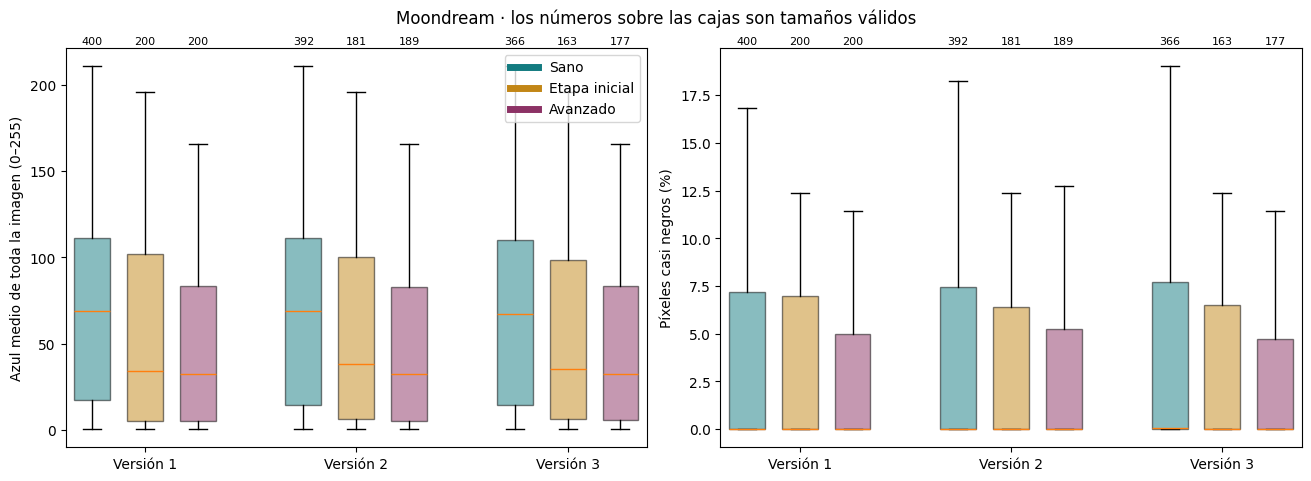

In [6]:
if not HROWS.empty:
    moon_history = HROWS.loc[HROWS.coleccion.eq(MOON)].rename(
        columns={"id_imagen": "id", "etiqueta": "clase", "particion": "split"})
    moon_rgb = collect_color(moon_history[["id", "clase", "split"]])
    moon_history = moon_history.merge(moon_rgb.drop(columns=["clase", "split"]), on="id", validate="one_to_one")
    population = [moon_history.assign(versión="Original (carpetas)")]
    if len(REF):
        ref = REF.merge(moon_history.drop(columns=["clase", "split"]), on="id", validate="one_to_one")
        print(f"Cruce de la reconstrucción con mediciones por ruta: {len(ref)}/{len(REF)}.")
        population.append(ref.assign(versión="Referencia de Andrés reconstruida" if not REF_CONFIRMED else "Referencia de Andrés aportada"))
    if not ELIGIBLE.empty:
        audited = ELIGIBLE.loc[ELIGIBLE.coleccion.eq(MOON), ["id", "clase", "split"]].merge(
            moon_history.drop(columns=["clase", "split"]), on="id", validate="one_to_one")
        population.append(audited.assign(versión="Elegible con auditoría ampliada"))
    comparison = pd.concat(population, ignore_index=True)
    interest = ["R", "G", "B", "brillo_mediano_yn", "negro_pct", "region_pct", "laplaciano_lado512"]
    desc_moon = percentile_table(comparison, ["versión", "clase"], interest)
    wraps = percentile_table(comparison, ["versión", "clase"], ["pad_negro", "pad_gris"])
    padding = comparison.groupby(["versión", "clase"])[["pad_negro", "pad_gris"]].agg(["size", "mean"])
    display(padding.round(3))
    display(desc_moon.round(2))
    medians = percentile_table(comparison, ["versión", "split", "clase"], interest)
    medians.to_csv(RUN / "03_moondream_por_split.csv", index=False)
    display(medians.loc[medians.medida.isin(["B", "negro_pct"])].round(2))
    fig, panels = plt.subplots(1, 2, figsize=(13, 4.7), layout="constrained")
    for ax, metric, unit in zip(panels, ["B", "negro_pct"], ["Azul medio de toda la imagen (0–255)", "Píxeles casi negros (%)"]):
        versions = comparison.versión.unique()
        for c, label in enumerate(ENC):
            for j, v in enumerate(versions):
                local = comparison.loc[comparison.clase.eq(label) & comparison.versión.eq(v), metric].dropna()
                position = j * 4 + c
                bp = ax.boxplot(local, positions=[position], widths=.68, patch_artist=True, showfliers=False)
                bp["boxes"][0].set_facecolor(COLORS[c])
                bp["boxes"][0].set_alpha(.5)
                ax.text(position, 1.01, str(len(local)), transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
        ax.set_xticks(np.arange(len(versions)) * 4 + 1, [f"Versión {i+1}" for i in range(len(versions))])
        ax.set(ylabel=unit)
    panels[0].legend(handles=[plt.Line2D([0], [0], color=COLORS[i], lw=5, label=s) for i, s in enumerate(CLASSES)])
    fig.suptitle("Moondream · los números sobre las cajas son tamaños válidos")
    print("Versión 1 a", len(versions), ":", " · ".join(versions))
    plt.show()

Las cajas permiten contrastar las clases dentro de cada versión de Moondream. Los tres grupos de cajas comparten escala y usan poblaciones superpuestas. La comparación describe la sensibilidad de la distribución al cambio de representantes. Las categorías clínicas proceden de las carpetas locales.

### Distribuciones entre fuentes y dentro de fuente

Se usan los representantes de la comparación histórica para contrastar fuentes. Las clases se desglosan dentro de cada colección y esquema, excluyendo los grupos históricos con conflicto. Se generan distribuciones acumuladas, cajas y mosaicos reproducibles basados en el orden de brillo.

,coleccion,medida,n,válidos,p25,mediana,p75,faltantes,RIC
0,ACRIMA,brillo_mediano_yn,703,703,92.00,110.00,126.00,0,34.00
1,RIM-ONE DL,brillo_mediano_yn,447,447,63.00,85.00,101.00,0,38.00
2,EyePACS REAL,brillo_mediano_yn,200,199,51.50,77.00,107.00,1,55.50
3,EyePACS TRAIN,brillo_mediano_yn,93,93,97.00,114.00,123.00,0,26.00
4,Moondream Staged,brillo_mediano_yn,706,705,65.00,121.00,171.00,1,106.00
...,...,...,...,...,...,...,...,...,...
80,ACRIMA,extension_y,703,703,1.00,1.00,1.00,0,0.00
81,RIM-ONE DL,extension_y,447,447,1.00,1.00,1.00,0,0.00
82,EyePACS REAL,extension_y,200,199,0.83,1.00,1.00,1,0.17
83,EyePACS TRAIN,extension_y,93,93,0.84,0.85,0.85,0,0.00


,coleccion,esquema_etiqueta,etiqueta,medida,n,válidos,p25,mediana,p75,faltantes,RIC
0,ACRIMA,binaria_clinica_acrima,normal,brillo_mediano_yn,308,308,102.00,114.50,130.00,0,28.00
1,ACRIMA,binaria_clinica_acrima,glaucoma,brillo_mediano_yn,395,395,83.50,104.00,125.00,0,41.50
2,RIM-ONE DL,binaria_clinica_rimone,glaucoma,brillo_mediano_yn,162,162,64.25,86.00,102.00,0,37.75
3,RIM-ONE DL,binaria_clinica_rimone,normal,brillo_mediano_yn,285,285,62.00,85.00,101.00,0,39.00
4,EyePACS REAL,cribado_rg_nrg_local,glaucoma,brillo_mediano_yn,100,99,52.00,74.00,107.00,1,55.00
5,EyePACS REAL,cribado_rg_nrg_local,normal,brillo_mediano_yn,100,100,51.75,78.00,105.75,0,54.00
6,EyePACS TRAIN,binaria_carpeta_beh,glaucoma,brillo_mediano_yn,51,51,97.00,109.00,119.00,0,22.00
7,EyePACS TRAIN,binaria_carpeta_beh,normal,brillo_mediano_yn,41,41,102.00,117.00,126.00,0,24.00
8,Moondream Staged,estadio_carpeta_moondream,advanced,brillo_mediano_yn,177,177,62.00,108.00,162.00,0,100.00
9,Moondream Staged,estadio_carpeta_moondream,early,brillo_mediano_yn,163,163,54.00,111.00,166.50,0,112.50


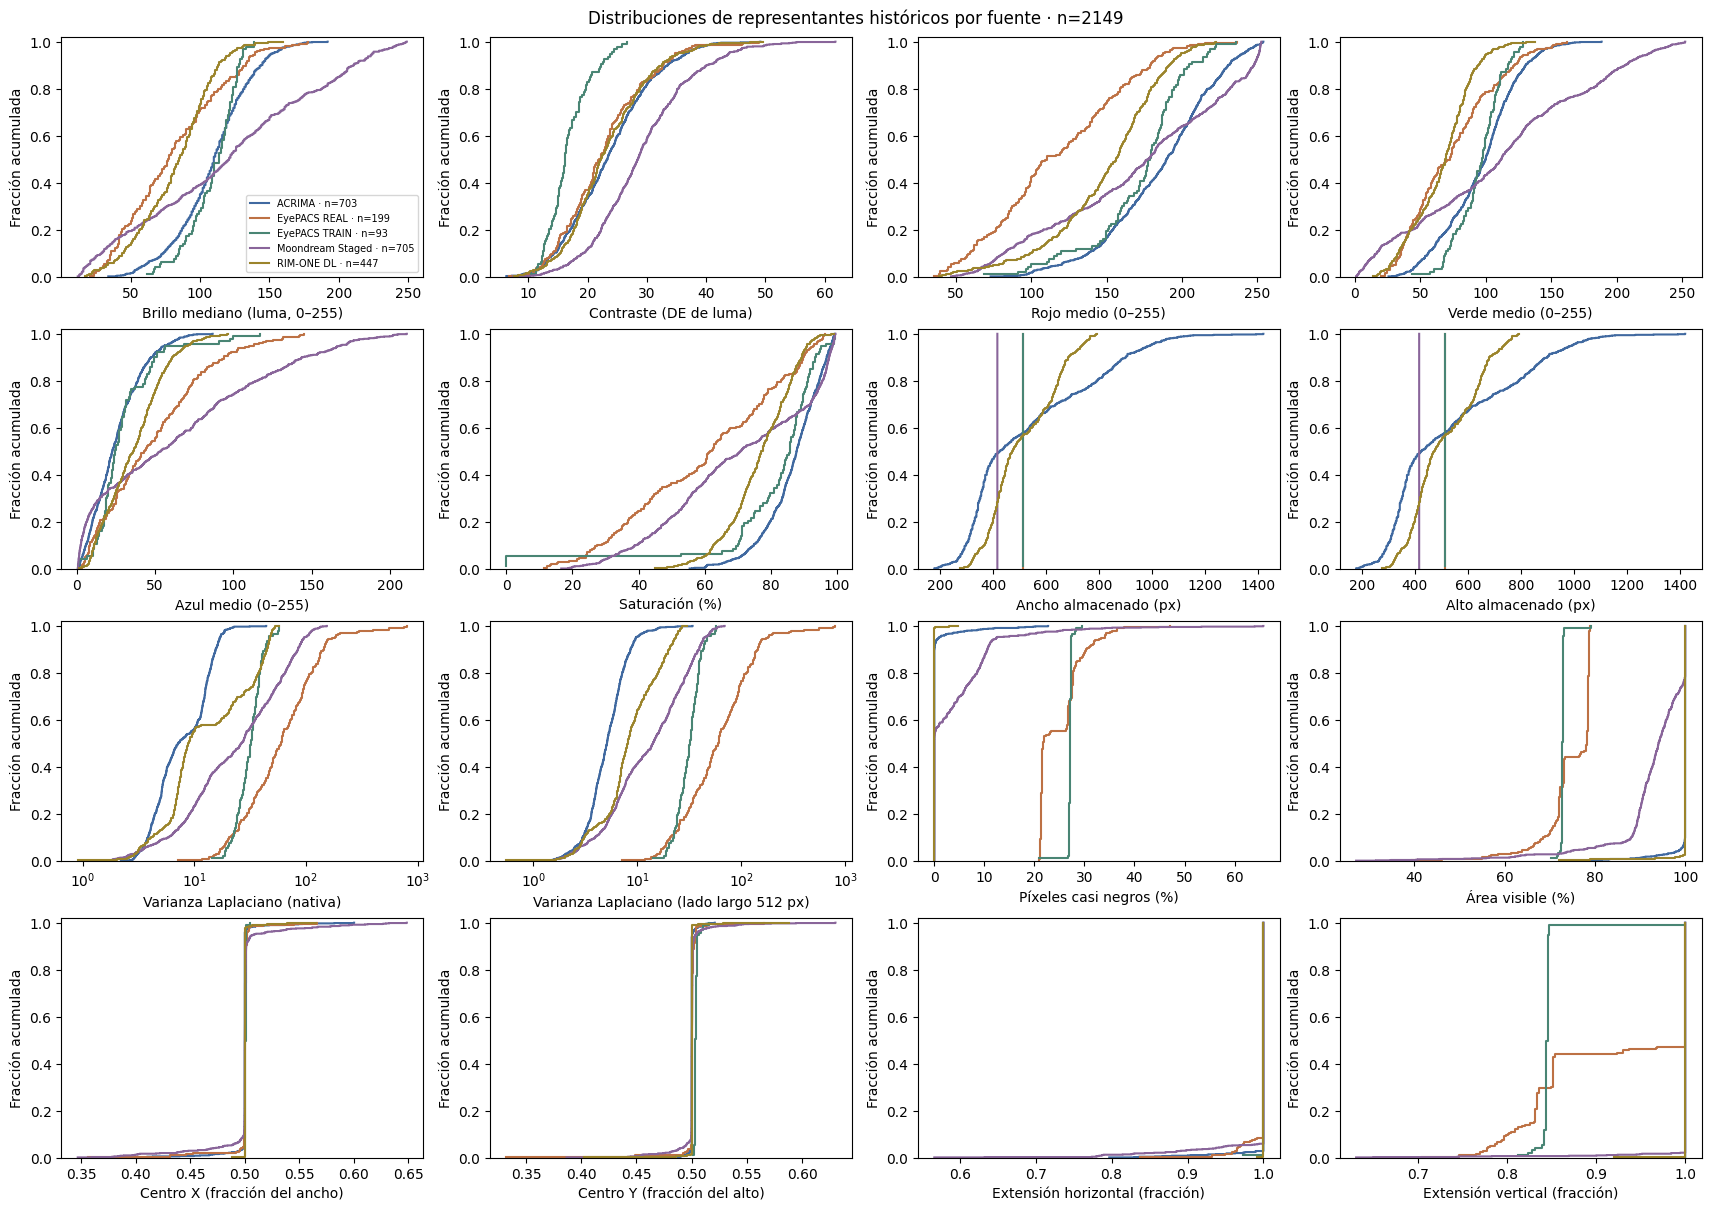

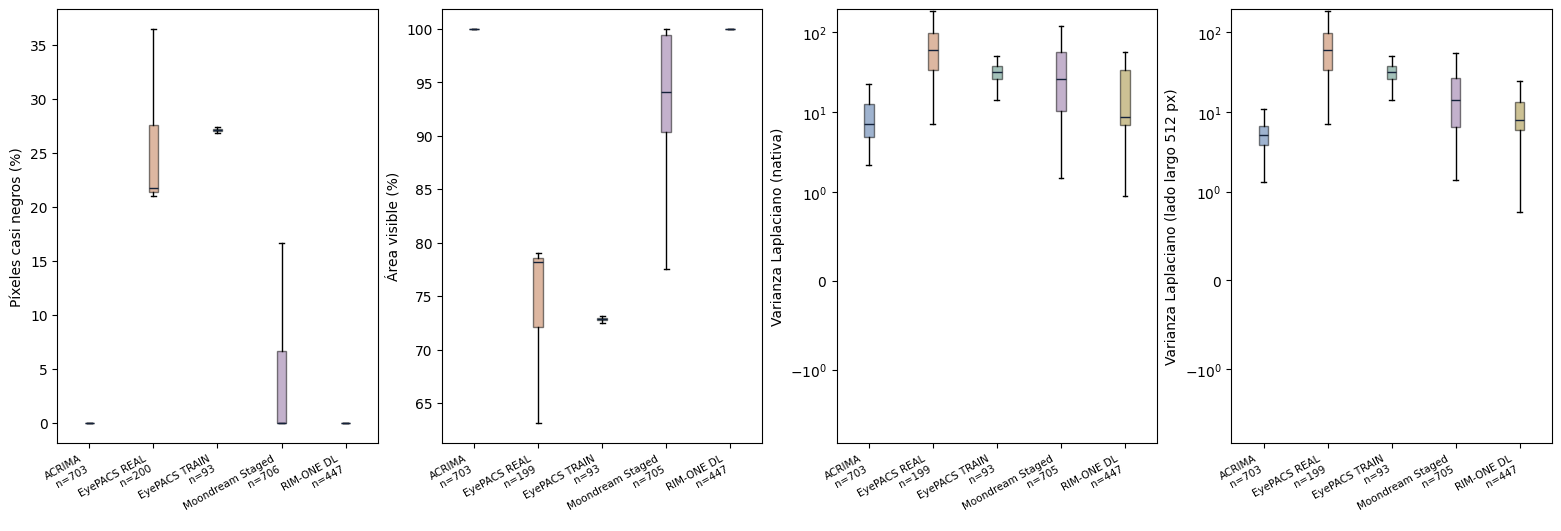

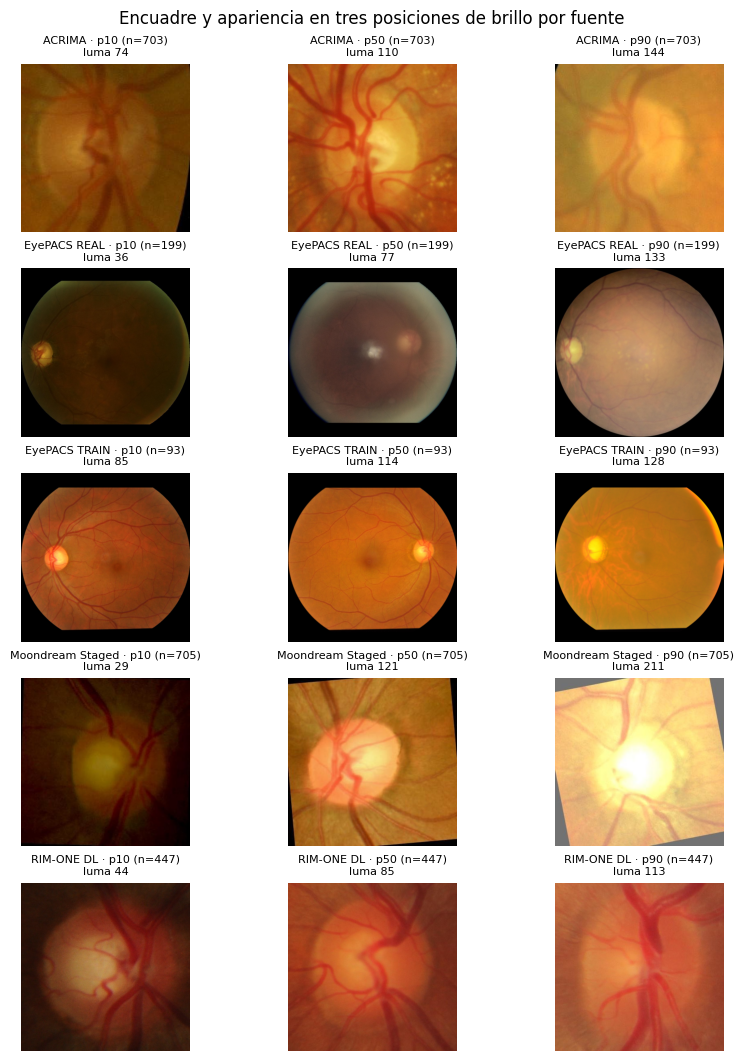

In [7]:
if not HROWS.empty:
    sources = HROWS.loc[HROWS.en_comparacion_fuentes.eq(True)].copy()
    profile = percentile_table(sources, ["coleccion"], FEATURES)
    labels_profile = percentile_table(
        HROWS.loc[HROWS.coleccion.isin([MOON, *COHORTS, "EyePACS TRAIN"]) & HROWS.en_resumen_grupo.eq(True)
                    & HROWS.conflicto_etiqueta_grupo.ne(True) & HROWS.etiqueta.notna()],
        ["coleccion", "esquema_etiqueta", "etiqueta"], FEATURES)
    profile.to_csv(RUN / "03_caracteristicas_por_fuente.csv", index=False)
    labels_profile.to_csv(RUN / "03_caracteristicas_por_etiqueta.csv", index=False)
    display(profile.round(2))
    display(labels_profile.loc[labels_profile.medida.isin(["brillo_mediano_yn", "b_media", "negro_pct", "region_pct"])].round(2))
    plots = ["brillo_mediano_yn", "contraste_de_yn", "r_media", "g_media", "b_media", "saturacion_media_pct",
             "ancho_px", "alto_px", "laplaciano_nativo", "laplaciano_lado512", "negro_pct", "region_pct",
             "centro_x", "centro_y", "extension_x", "extension_y"]
    fig, axes = plt.subplots(4, 4, figsize=(17, 12), layout="constrained")
    for ax, metric in zip(axes.ravel(), plots):
        for color, (source, group) in zip(SOURCE_COLORS, sources.groupby("coleccion")):
            vals = group[metric].dropna().sort_values().to_numpy()
            if len(vals):
                ax.step(vals, np.arange(1, len(vals)+1) / len(vals), color=color, where="post",
                        label=f"{source} · n={len(vals)}")
        if metric.startswith("laplaciano"):
            ax.set_xscale("symlog", linthresh=1)
        ax.set(xlabel=FEATURES[metric], ylabel="Fracción acumulada", ylim=(0, 1.02))
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"Distribuciones de representantes históricos por fuente · n={len(sources)}")
    plt.show()

    focus = ["negro_pct", "region_pct", "laplaciano_nativo", "laplaciano_lado512"]
    fig, axes = plt.subplots(1, 4, figsize=(15.5, 5.2), layout="constrained")
    for ax, metric in zip(axes, focus):
        for index, (source, group) in enumerate(sources.groupby("coleccion")):
            vals = group[metric].dropna()
            ax.boxplot(vals, positions=[index], patch_artist=True, showfliers=False,
                       boxprops={"facecolor": SOURCE_COLORS[index], "alpha": .5},
                       medianprops={"color": "#14223a"})
        ax.set_xticks(range(sources.coleccion.nunique()), [f"{name}\nn={group[metric].count()}"
                      for name, group in sources.groupby("coleccion")], rotation=29, ha="right", fontsize=7.5)
        if metric.startswith("laplaciano"):
            ax.set_yscale("symlog", linthresh=1)
        ax.set(ylabel=FEATURES[metric])
    plt.show()

    fig, axes = plt.subplots(sources.coleccion.nunique(), 3, figsize=(8, 2.1 * sources.coleccion.nunique()),
                             squeeze=False, layout="constrained")
    for (name, group), panels in zip(sources.groupby("coleccion"), axes):
        valid = group.dropna(subset=["brillo_mediano_yn"]).sort_values(["brillo_mediano_yn", "id_imagen"])
        indices = np.rint(np.array([.1, .5, .9]) * (len(valid) - 1)).astype(int)
        for ax, (_, row), quantile in zip(panels, valid.iloc[indices].iterrows(), (10, 50, 90)):
            ax.axis("off")
            if (ROOT / row.id_imagen).is_file():
                ax.imshow(image_rgb(row.id_imagen))
            ax.set_title(f"{name} · p{quantile} (n={len(valid)})\nluma {row.brillo_mediano_yn:g}", fontsize=8)
    fig.suptitle("Encuadre y apariencia en tres posiciones de brillo por fuente")
    plt.show()

Las curvas hacen comparables las escalas por métrica. Las cajas de Laplaciano permiten ver cuánto cambia la descripción al fijar el lado largo en 512 px. Los mosaicos muestran diferencias de campo visible, iluminación y relleno. Fuente, recorte y captura covarían en estas copias, por lo que estas diferencias tienen una interpretación descriptiva.

### Originales frente a derivados

Se compara derivada menos original para pares cuya transformación se pudo reproducir por bytes o por tolerancia RGB. Cada grupo y transformación aporta un par. Se recalculan medianas, tamaños válidos y faltantes y se cotejan con el resumen histórico.

,fuente,transformacion,medida,n,válidos,p25,mediana,p75,faltantes,RIC
0,ACRIMA,escalar,brillo_mediano_yn,703,703,0.000,0.000,0.000,0,0.000
1,EyePACS REAL,recortar_color,brillo_mediano_yn,200,199,-3.000,25.000,51.000,1,54.000
2,Moondream Staged,escalar,brillo_mediano_yn,706,705,0.000,0.000,0.000,1,0.000
3,RIM-ONE DL,escalar,brillo_mediano_yn,447,447,0.000,0.000,0.000,0,0.000
4,ACRIMA,emular_web,brillo_mediano_yn,40,40,0.000,0.000,0.000,0,0.000
5,ACRIMA,escalar,contraste_de_yn,703,703,-0.006,-0.000,0.004,0,0.009
6,EyePACS REAL,recortar_color,contraste_de_yn,200,199,-6.144,-2.268,1.178,1,7.321
7,Moondream Staged,escalar,contraste_de_yn,706,705,-0.068,-0.019,-0.005,1,0.062
8,RIM-ONE DL,escalar,contraste_de_yn,447,447,-0.008,0.001,0.004,0,0.012
9,ACRIMA,emular_web,contraste_de_yn,40,40,-0.114,-0.079,-0.059,0,0.055


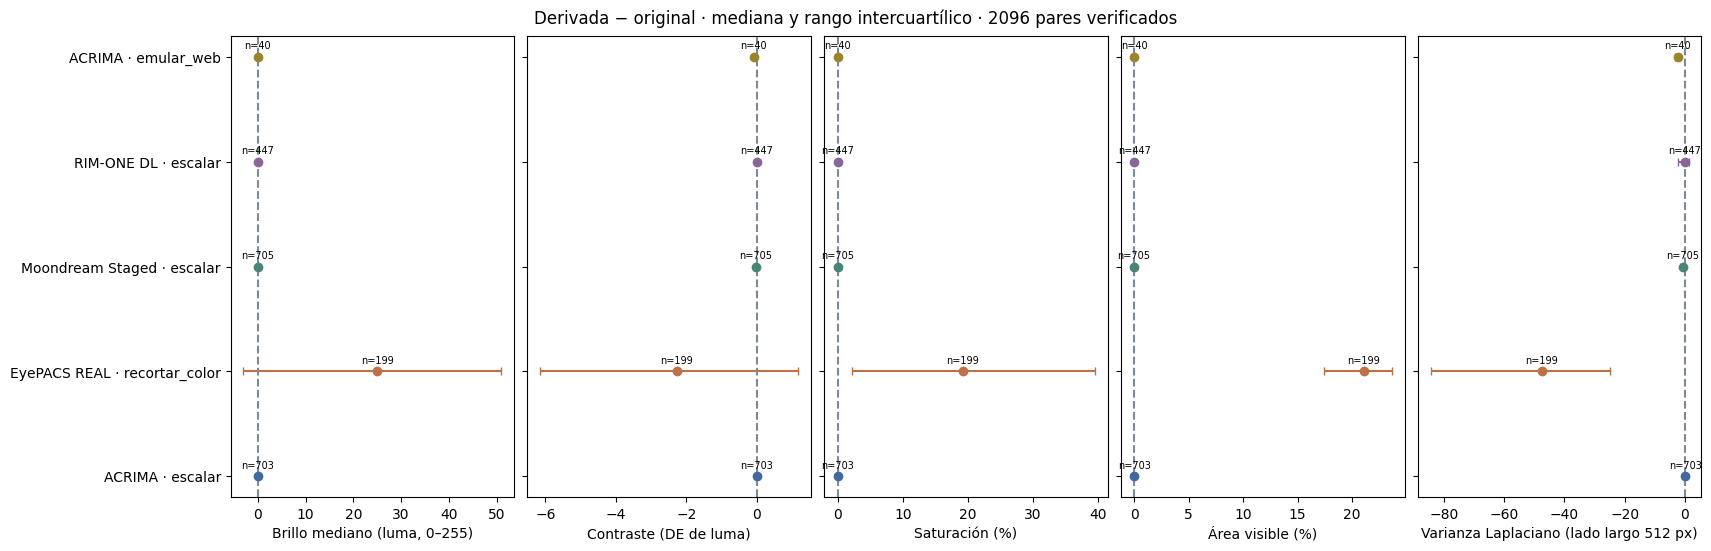

EyePACS REAL · n=199 pares con brillo: mediana +25.0 niveles de luma; cambio mediano de área +21.0 puntos porcentuales.


In [8]:
if not PAIR.empty and not HROWS.empty:
    pair_metrics = ["brillo_mediano_yn", "contraste_de_yn", "saturacion_media_pct", "region_pct", "laplaciano_lado512"]
    pair_summary = percentile_table(PAIR, ["fuente", "transformacion"], pair_metrics)
    comparison = pair_summary.merge(PAIR_SUMMARY, left_on=["fuente", "transformacion", "medida"],
                                    right_on=["fuente", "transformacion", "metrica"], suffixes=("", "_hist"))
    assert len(comparison) == len(pair_summary)
    assert comparison.n.eq(comparison.n_total).all()
    assert comparison.válidos.eq(comparison.n_validas).all()
    assert np.allclose(comparison.mediana, comparison.mediana_hist, equal_nan=True, atol=.0001)
    display(pair_summary.round(3))
    pair_summary.to_csv(RUN / "03_cambios_pareados.csv", index=False)
    pair_summary["grupo"] = pair_summary.fuente + " · " + pair_summary.transformacion
    fig, axes = plt.subplots(1, len(pair_metrics), figsize=(17, 5.4), sharey=True, layout="constrained")
    for ax, metric in zip(axes, pair_metrics):
        selected = pair_summary.loc[pair_summary.medida.eq(metric)]
        for i, row in enumerate(selected.itertuples()):
            if row.válidos:
                ax.errorbar(row.mediana, i, xerr=[[row.mediana - row.p25], [row.p75 - row.mediana]],
                            fmt="o", color=SOURCE_COLORS[i % len(SOURCE_COLORS)], capsize=3)
                ax.annotate(f"n={row.válidos}", (row.mediana, i), xytext=(0, 6), textcoords="offset points",
                            ha="center", fontsize=7)
        ax.axvline(0, ls="--", color="#7e8996")
        ax.set(xlabel=FEATURES[metric], yticks=range(len(selected)), yticklabels=selected.grupo)
    fig.suptitle(f"Derivada − original · mediana y rango intercuartílico · {len(PAIR)} pares verificados")
    plt.show()
    if "EyePACS REAL" in set(PAIR.fuente):
        eye = pair_summary.loc[pair_summary.fuente.eq("EyePACS REAL")].set_index("medida")
        print(f"EyePACS REAL · n={eye.loc['brillo_mediano_yn','válidos']} pares con brillo: "
              f"mediana {eye.loc['brillo_mediano_yn','mediana']:+.1f} niveles de luma; "
              f"cambio mediano de área {eye.loc['region_pct','mediana']:+.1f} puntos porcentuales.")

Los puntos muestran medianas de diferencias y las barras muestran el rango intercuartílico. EyePACS REAL incluye recorte y ajuste de color en la misma transformación. Las diferencias pareadas corresponden al procesamiento combinado. La emulación web deriva de ACRIMA y aporta evidencia sobre ese proceso.

### Características y errores del ganador

Se comprueba la presencia de predicciones verificadas del checkpoint de Andrés y su equivalencia por ruta y hash antes de estimar aciertos, FP y FN por cohorte. La ruta de predicciones puede configurarse con `FABIAN_PREDICCIONES_ANDRES`. Se muestran cobertura y medidas válidas si hay predicciones que cumplan el protocolo.

In [9]:
pred_path = Path(os.environ.get("FABIAN_PREDICCIONES_ANDRES", OUTPUT / "completo/predicciones_andres_verificadas.csv"))
pred_verified = (pred_path.is_file() and REF_CONFIRMED and CHECKPOINT_SHA and CHECKPOINT.is_file()
                 and digest(CHECKPOINT) == CHECKPOINT_SHA and not ELIGIBLE.empty)
if not pred_verified:
    print(f"Cruce pendiente · se requieren checkpoint verificable, manifiesto original y predicciones por ruta verificada ({pred_path}).")
else:
    pred = pd.read_csv(pred_path)
    assert pred.id.is_unique
    assert pred.sha256_checkpoint.eq(CHECKPOINT_SHA).all()
    assert pred.sha256_split.eq(scenario_signature(REF)).all()
    assert pred.sha256_elegibilidad.eq(scenario_signature(ELIGIBLE[["id", "split", "grupo"]])).all()
    assert pred.pred2_original.isin([0, 1]).all()
    assert pred.pred3_original.isin([0, 1, 2]).all()
    assert pred.pred2_original.eq(pred.pred3_original.gt(0).astype(int)).all()
    assert pred.p_binaria.between(0., 1.000001).all()
    eligible_test = ELIGIBLE.loc[ELIGIBLE.split.isin(["test", "externo"]), ["id", "y2", "coleccion"]]
    joined = eligible_test.merge(pred, on=["id", "y2"], how="left", validate="one_to_one", indicator="predicción")
    features = HROWS[["id_imagen", "sha256_archivo", *FEATURES]].rename(
        columns={"id_imagen": "id", "sha256_archivo": "sha256_features"})
    joined = joined.merge(features, on="id", how="left", validate="one_to_one")
    joined["cruce válido"] = joined["predicción"].eq("both") & joined.sha256_archivo.eq(joined.sha256_features)
    display(joined.groupby("coleccion")["cruce válido"].agg(denominador="size", n_enlazadas="sum"))
    joined = joined.loc[joined["cruce válido"]].copy()
    if len(joined):
        joined["resultado"] = np.select([joined.y2.eq(joined.pred2_original), joined.y2.eq(0)],
                                        ["Acierto", "Falso positivo"], default="Falso negativo")
        display(percentile_table(joined, ["coleccion", "resultado"], FEATURES).round(3))
        for source, group in joined.groupby("coleccion"):
            fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
            for ax, metric in zip(axes, ("brillo_mediano_yn", "negro_pct", "region_pct")):
                for i, (label, rows) in enumerate(group.groupby("resultado")):
                    values = rows[metric].dropna()
                    if len(values):
                        ax.boxplot(values, positions=[i], widths=.55)
                    ax.text(i, 1, f"{label}\nn={len(values)}", transform=ax.get_xaxis_transform(),
                            ha="center", fontsize=8)
                ax.set(ylabel=FEATURES[metric], xticks=[])
            fig.suptitle(f"{source} · aciertos y errores al detectar glaucoma · n={len(group)}")
            plt.show()

Cruce pendiente · se requieren checkpoint verificable, manifiesto original y predicciones por ruta verificada (C:\Users\fabi2\AppData\Local\glaucoma-fabian\completo\predicciones_andres_verificadas.csv).


## Interpretación y limitaciones

La comparación entre fuentes examina archivos preparados con encuadres distintos. La comparación de versiones Moondream evalúa cómo cambia su descripción al reagrupar coincidencias visibles. Las diferencias pareadas corresponden a derivados con procedencia local comprobada. La cobertura histórica de máscaras alineadas de disco óptico es cero, por lo que el tamaño de la región visible no mide el tamaño del disco. Las asociaciones entre características y errores, si se dispone de predicciones identificadas, son descriptivas y pueden reflejar fuente, clase o calidad de archivo.

En los test de Moondream, la mediana del azul medio en Avanzado pasó de 45,3 (n=50) en el split original a 8,7 en la reconstrucción (n=29) y 8,7 tras la auditoría ampliada (n=25). La comparación incorpora cambios de composición y de asignación al test. En los 199 pares EyePACS REAL con luma medible, el procesamiento combinado cambió la mediana de luma en +25 niveles (p25–p75 -3 a +51).